# Laboratorio: una red neuronal contra el PM12

**Módulo 6 · Unidad 5 · CEC EPN · 24-11-2026**

**Parte 1.** Primero entendemos cómo aprende una red con el ejemplo más simple: una red que descubre sola la fórmula para pasar de grados Celsius a Fahrenheit. Vemos la red dibujada, el entrenamiento, los pesos que aprende y qué pasa por dentro (retropropagación y descenso del gradiente).

**Parte 2.** Después vamos a programar, todos juntos y paso a paso, dos redes neuronales con TensorFlow (Keras) para pronosticar la inflación mensual del Ecuador, y las vamos a comparar con el **promedio de los últimos 12 meses (PM12)**:

| Modelo | Qué recibe | Desde qué año aprende |
|---|---|---|
| **Modelo A**: la red con mucha información | la inflación de los 12 meses anteriores | 2006 |
| **Modelo B**: la red simple | el PM12 y el mes del año | 2015 |

Al final escogerás el modelo que prefieres y explicarás por qué.

**Antes de empezar:** en Colab, Archivo → Guardar una copia en Drive. Ejecuta cada celda con Shift + Enter.

:**Nombre del estudiante:** Carlos Dávila Pazmiño

# Parte 1 · Primero entendemos: una red que pasa de Celsius a Fahrenheit

## Paso 1.1 · Las librerías

In [4]:
%pip install -q numpy pandas matplotlib scikit-learn tensorflow

## Paso 1.2 · Los datos

In [30]:
# Escribe aquí el código del paso
celsius = np.array([-40,-10,0,8,15,22,38], dtype=float)
fahrenheit = np.array([-40,14,32,46,59,72,100], dtype=float)
print(pd.DataFrame({'Celsius':celsius, 'Fahrenheit': fahrenheit}).to_string(index=False))

 Celsius  Fahrenheit
   -40.0       -40.0
   -10.0        14.0
     0.0        32.0
     8.0        46.0
    15.0        59.0
    22.0        72.0
    38.0       100.0


## Paso 1.3 · La red más simple: una sola neurona

In [31]:
# Escribe aquí el código del paso
keras.utils.set_random_seed(42)
neurona = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(1),
])
neurona.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1),
                loss='mean_squared_error')
neurona.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

## Paso 1.4 · Dibujar la red

In [32]:
# Celda ya escrita: dibuja cualquier red pequeña de Keras con sus neuronas, conexiones y pesos.
# Solo hay que ejecutarla; después se usa así: dibujar_red(modelo)
def dibujar_red(modelo, titulo=''):
    capas = [modelo.layers[0].get_weights()[0].shape[0]] + [c.units for c in modelo.layers]
    x = np.linspace(0, 1, len(capas))
    pos = [[(x[i], (j + 1) / (n + 1)) for j in range(n)] for i, n in enumerate(capas)]
    fig, ax = plt.subplots(figsize=(2.2 * len(capas) + 1, 3.2))
    for i, capa in enumerate(modelo.layers):
        W, b = capa.get_weights()
        for a, (xa, ya) in enumerate(pos[i]):
            for d, (xd, yd) in enumerate(pos[i + 1]):
                ax.plot([xa, xd], [ya, yd], color='#4A6FA5' if W[a, d] > 0 else '#DF1F1C', lw=0.5 + min(abs(W[a, d]), 3))
                if W.size <= 12:
                    t = 0.5 if W.size == 1 else 0.22 + 0.2 * d          # escalonar las etiquetas para que no se pisen
                    ax.text(xa + t * (xd - xa), ya + t * (yd - ya), f'{W[a, d]:.2f}', fontsize=8, ha='center', va='center',
                            bbox=dict(fc='white', ec='none', pad=0.5))
        for d, (xd, yd) in enumerate(pos[i + 1]):
            ax.text(xd, yd - 0.14, f'b={b[d]:.1f}', fontsize=8, ha='center', color='gray', zorder=4)
    for i, capa_pos in enumerate(pos):
        for (xx, yy) in capa_pos:
            ax.scatter(xx, yy, s=700, color='#C98A1A' if 0 < i < len(pos) - 1 else '#16243D', zorder=3)
    nombres = ['entrada'] + [f'oculta {i}' for i in range(1, len(capas) - 1)] + ['salida']
    for xx, nom in zip(x, nombres):
        ax.text(xx, -0.02, nom, ha='center', fontsize=10)
    ax.set_xlim(-0.15, 1.15); ax.set_ylim(-0.1, 1.05); ax.axis('off'); ax.set_title(titulo)
    plt.show()

print('Listo: ya se puede usar dibujar_red(modelo)')

Listo: ya se puede usar dibujar_red(modelo)


### Paso 1.5 · La red antes de entrenar

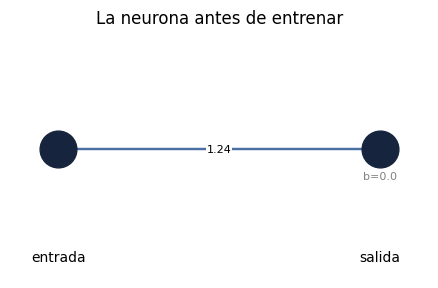

In [33]:
# Escribe aquí el código del paso
dibujar_red(neurona, 'La neurona antes de entrenar')

## Paso 1.6 · Entrenar: el fit

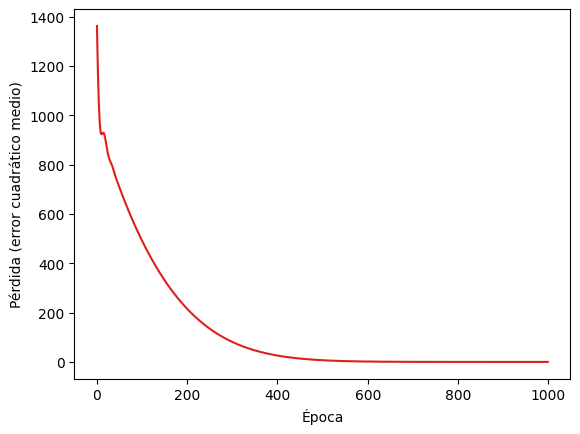

In [34]:
# Escribe aquí el código del paso
historia = neurona.fit(celsius, fahrenheit, epochs=1000, verbose=0)

plt.plot(historia.history['loss'], color='#DF1F1C')
plt.xlabel('Época'); plt.ylabel('Pérdida (error cuadrático medio)')
plt.show()

## Paso 1.7 · Predecir y mirar lo que aprendió

La red dice que 31 °C = 87.67 °F
Peso aprendido: 1.7981 (la fórmula usa 1,8)
Sesgo aprendido: 31.9301 (la fórmula usa 32)


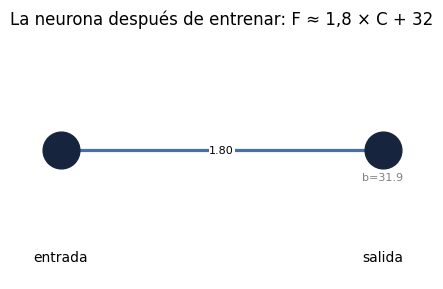

In [35]:
# Escribe aquí el código del paso
print(f'La red dice que 31 °C = {neurona.predict(np.array([31.0]), verbose=0)[0, 0]:.2f} °F')

# Lo que aprendió: el peso y el sesgo
peso_aprendido, sesgo_aprendido = neurona.layers[0].get_weights()
print(f'Peso aprendido: {peso_aprendido[0, 0]:.4f} (la fórmula usa 1,8)')
print(f'Sesgo aprendido: {sesgo_aprendido[0]:.4f} (la fórmula usa 32)')
dibujar_red(neurona, 'La neurona después de entrenar: F ≈ 1,8 × C + 32')


## Para leer: las piezas de una red en Keras

**Tres formas de armar un modelo en Keras**

| Forma | Cómo se ve | Cuándo se usa |
|---|---|---|
| **Sequential** (la nuestra) | una lista de capas, una detrás de otra | redes en línea recta: la mayoría de los casos simples |
| **API funcional** | se conectan las capas como piezas: `salida = capa(entrada)` | redes con varias entradas o salidas, o con ramas |
| **Subclases** (`class MiRed(keras.Model)`) | se programa la red como una clase de Python | investigación y redes muy a medida |

**Tipos de redes neuronales**

| Tipo | Capa principal en Keras | Para qué datos |
|---|---|---|
| **Densa o perceptrón multicapa** (la nuestra) | `Dense` | tablas: clientes, meses con sus variables |
| **Convolucional (CNN)** | `Conv2D` | imágenes: fotos, radiografías, cheques |
| **Recurrente (RNN, LSTM, GRU)** | `LSTM`, `GRU` | secuencias: series de tiempo largas, texto, audio |
| **Transformer** | `MultiHeadAttention` | texto y lenguaje (los modelos como ChatGPT o Claude) |

**Optimizadores: la regla para dar el paso**

| Optimizador | Idea en una frase |
|---|---|
| **SGD** (descenso del gradiente estocástico) | el paso básico: nuevo = actual − tasa × gradiente, con el mismo tamaño para todos los pesos |
| **SGD con momentum** | como una pelota que baja la montaña: acumula velocidad y no se frena en cada bache |
| **Adagrad** | da pasos más chicos a los pesos que ya se movieron mucho |
| **RMSprop** | ajusta el paso de cada peso según qué tan grandes han sido sus gradientes recientes |
| **Adam** (el que usamos) | junta momentum y RMSprop: cada peso tiene su propio tamaño de paso y además lleva impulso |

**¿Por qué Adam?** Porque casi siempre funciona bien sin tener que afinar mucho: ajusta solo el tamaño del paso de cada peso, avanza rápido al principio y con cuidado cerca del mínimo. Por eso es la opción por defecto en la mayoría de los proyectos. El SGD simple puede funcionar igual o mejor, pero hay que buscarle bien la tasa de aprendizaje (en el paso 1.9 lo vimos: con 0,001 llega; con 0,002 la cuenta explota).

# Parte 2 · La red contra la inflación

Ahora que sabemos cómo funciona una red, la usamos con un problema real: pronosticar la inflación mensual del Ecuador.

## Paso 2.1 · Cargar las librerías y los datos

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.preprocessing import StandardScaler

url = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos/series_economicas.csv'
series = pd.read_csv(url, parse_dates=['fecha'], index_col='fecha')
inflacion = series['ipc_var_mensual'].loc['2005':'2026-08']
print('Keras', keras.__version__, '· meses de inflación:', len(inflacion))

Keras 3.13.2 · meses de inflación: 260


## Paso 2.2 · Mirar la serie

count    260.00
mean       0.21
std        0.37
min       -0.99
25%       -0.00
50%        0.17
75%        0.40
max        1.52
Name: ipc_var_mensual, dtype: float64


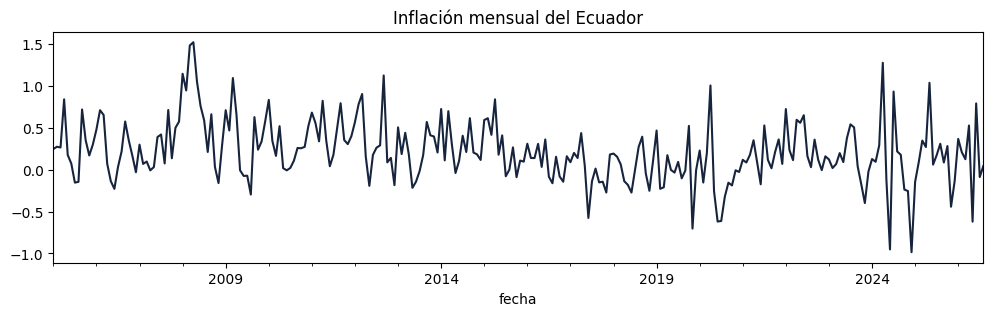

In [42]:
# Escribe aquí el código del paso
print(inflacion.describe().round(2))
inflacion.plot(color='#16243D', figsize=(12, 3), title='Inflación mensual del Ecuador')
plt.show()

## Paso 2.3 · Armar la tabla

In [47]:
# Escribe aquí el código del paso
tabla = pd.DataFrame({'inflacion': inflacion})
for k in range(1,13):
  tabla[f'rezago_{k}'] = inflacion.shift(k)
tabla['pm12'] = inflacion.shift(1).rolling(12).mean()

meses = pd.get_dummies(tabla.index.month, prefix='mes', dtype=float)
meses.index = tabla.index
tabla = tabla.join(meses)

tabla = tabla.dropna()
tabla[['inflacion', 'rezago_1', 'rezago_12', 'pm12', 'mes_1', 'mes_2', 'mes_3', 'mes_4', 'mes_5', 'mes_6']]

,inflacion,rezago_1,rezago_12,pm12,mes_1,mes_2,mes_3,mes_4,mes_5,mes_6
fecha,,,,,,,,,,
2006-01-01,0.478115,0.298181,0.244728,0.257897,1.0,0.0,0.0,0.0,0.0,0.0
2006-02-01,0.707808,0.478115,0.272185,0.277346,0.0,1.0,0.0,0.0,0.0,0.0
2006-03-01,0.651606,0.707808,0.263370,0.313648,0.0,0.0,1.0,0.0,0.0,0.0
2006-04-01,0.068475,0.651606,0.837390,0.346001,0.0,0.0,0.0,1.0,0.0,0.0
2006-05-01,-0.138012,0.068475,0.175113,0.281925,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...
2026-04-01,0.525567,0.123488,0.268531,0.192984,0.0,0.0,0.0,1.0,0.0,0.0
2026-05-01,-0.621261,0.525567,1.033814,0.214404,0.0,0.0,0.0,0.0,1.0,0.0
2026-06-01,0.788722,-0.621261,0.058797,0.076481,0.0,0.0,0.0,0.0,0.0,1.0


## Paso 2.4 · Separar Train y Test

In [63]:
# Escribe aquí el código del paso
train = tabla.loc[:'2024-12']
test = tabla.loc['2025-01':'2026-08']
print('Train:', len(train), '· Test:', len(test))

Train: 228 · Test: 20


## Paso 2.5 · La línea base: el PM12

In [64]:
# Escribe aquí el código del paso
error_pm12 = (test['inflacion'] - test['pm12']).abs().mean()
print(f'Error del PM12: {error_pm12:.3f} puntos porcentuales')

Error del PM12: 0.286 puntos porcentuales


## Paso 2.6 · Modelo A: la red con mucha información

### Paso 2.6.1 Elegir las columnas y normalizar

In [65]:
# Escribe aquí el código del paso
columnas_A = [f'rezago_{k}' for k in range(1, 13)]
train_A = train.loc['2006':]

escala_A = StandardScaler().fit(train_A[columnas_A])
X_train_A = escala_A.transform(train_A[columnas_A])
X_test_A = escala_A.transform(test[columnas_A])
y_train_A = train_A['inflacion'].values
print('Modelo A ·', len(columnas_A), 'entradas ·', len(train_A), 'meses para aprender (desde',
      train_A.index.min().strftime('%Y-%m') + ')')

Modelo A · 12 entradas · 228 meses para aprender (desde 2006-01)


### Paso 2.6.2 Crear la red

In [66]:
# Escribe aquí el código del paso
keras.utils.set_random_seed(42)
modelo_A = keras.Sequential([
    keras.Input(shape=(len(columnas_A),)),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(1),
])
modelo_A.compile(optimizer=keras.optimizers.Adam(learning_rate=0.003), loss='mae')
modelo_A.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113 (452.00 B)

 Trainable params: 113 (452.00 B)

 Non-trainable params: 0 (0.00 B)

### Paso 2.6.3 Entrenar

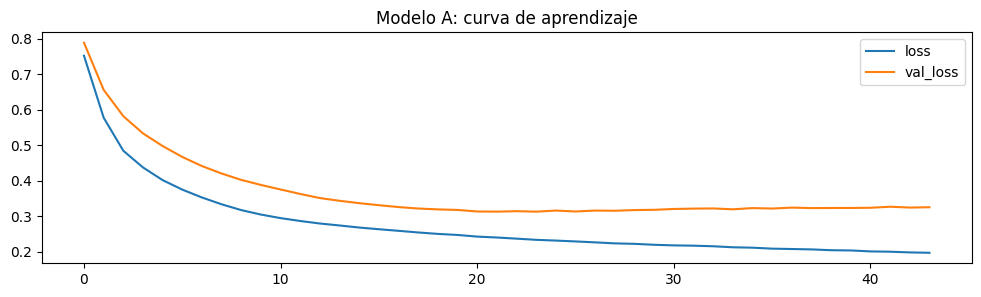

In [67]:
# Escribe aquí el código del paso
parada = keras.callbacks.EarlyStopping(restore_best_weights=True, patience=20)
historia_A = modelo_A.fit(X_train_A, y_train_A, epochs=300, batch_size=16, validation_split=0.2, callbacks=[parada], verbose=0)
pd.DataFrame(historia_A.history).plot(figsize=(12, 3), title ='Modelo A: curva de aprendizaje')
plt.show()

### Paso 2.6.4 Pronosticar y medir el error

In [70]:
# Escribe aquí el código del paso
pron_A = modelo_A.predict(X_test_A, verbose=0).ravel()
error_A = (test['inflacion'] - pron_A).abs().mean()
print(f'Error del Modelo A: {error_A:.3f} puntos porcentuales')

Error del Modelo A: 0.427 puntos porcentuales


## Paso 2.7 · Modelo B: la red simple

### Paso 2.7.1 Elegir las columnas y normalizar

In [73]:
# Escribe aquí el código del paso
columnas_B = ['pm12'] + [f'mes_{m}' for m in range(1,13)]
train_B = train.loc['2015':]

escala_B = StandardScaler().fit(train_B[columnas_B])
X_train_B = escala_B.transform(train_B[columnas_B])
X_test_B = escala_B.transform(test[columnas_B])
y_train_B = train_B['inflacion'].values
print('Modelo B ·', len(columnas_B), 'entradas ·', len(train_B), 'meses para aprender (desde',
      train_B.index.min().strftime('%Y-%m') + ')')

Modelo B · 13 entradas · 120 meses para aprender (desde 2015-01)


### Paso 2.7.2 Crear la red

In [74]:
# Escribe aquí el código del paso
keras.utils.set_random_seed(42)
modelo_B = keras.Sequential([
    keras.Input(shape=(len(columnas_B),)),
    keras.layers.Dense(8, activation='relu'),
    keras.layers.Dense(1),
])
modelo_B.compile(optimizer=keras.optimizers.Adam(learning_rate=0.003), loss='mae')
modelo_B.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 8)              │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121 (484.00 B)

 Trainable params: 121 (484.00 B)

 Non-trainable params: 0 (0.00 B)

### Paso 2.7.3 Entrenar

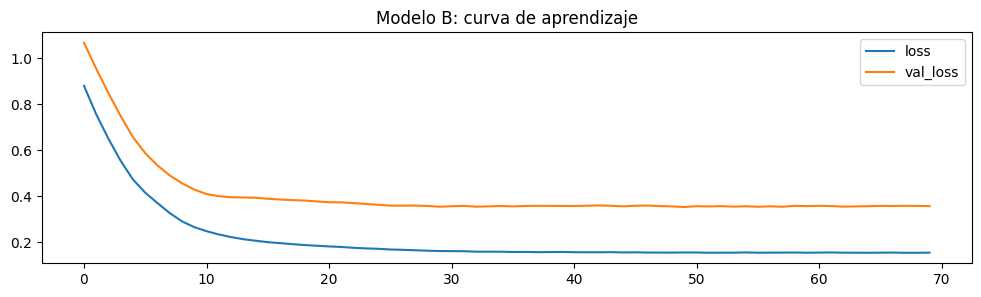

In [75]:
# Escribe aquí el código del paso
parada = keras.callbacks.EarlyStopping(restore_best_weights=True, patience=20)
historia_B = modelo_B.fit(X_train_B, y_train_B, epochs=300, batch_size=16, validation_split=0.2, callbacks=[parada], verbose=0)
pd.DataFrame(historia_B.history).plot(figsize=(12, 3), title ='Modelo B: curva de aprendizaje')
plt.show()

### Paso 2.7.4 Pronosticar y medir el error

In [79]:
# Escribe aquí el código del paso
pron_B = modelo_B.predict(X_test_B, verbose=0).ravel()
error_B = (test['inflacion'] - pron_B).abs().mean()
print(f'Error del Modelo B: {error_B:.3f} puntos porcentuales', f'Error del Modelo A: {error_A:.3f} puntos porcentuales', f'Error del Modelo pm12: {error_pm12:.3f} puntos porcentuales')

Error del Modelo B: 0.270 puntos porcentuales Error del Modelo A: 0.427 puntos porcentuales Error del Modelo pm12: 0.286 puntos porcentuales


### Paso 2.7.5 ¿Dónde están los pesos?

In [80]:
# Escribe aquí el código del paso
pesos, sesgos = modelo_B.layers[0].get_weights()
print('Pesos de la capa oculta:', pesos.shape, '(13 entradas * 8 neuronas) - sesgos: ', sesgos.shape)
print('Pesos que salen de las 8 neuronas: ', pesos[0].round(2))


Pesos de la capa oculta: (13, 8) (13 entradas * 8 neuronas) - sesgos:  (8,)
Pesos que salen de las 8 neuronas:  [ 0.23  0.24  0.13  0.35 -0.13  0.16  0.41 -0.08]


## Paso 2.8 · Comparar los tres

### Paso 2.8.1 La tabla

In [82]:
# Escribe aquí el código del paso
comparacion = pd.DataFrame({'Modelo': ['PM12', 'Modelo A', 'Modelo B'], 'Error MAE': [error_pm12, error_A, error_B]})
comparacion.round(3)

,Modelo,Error MAE
0,PM12,0.286
1,Modelo A,0.427
2,Modelo B,0.270


### Paso 2.8.2 El gráfico

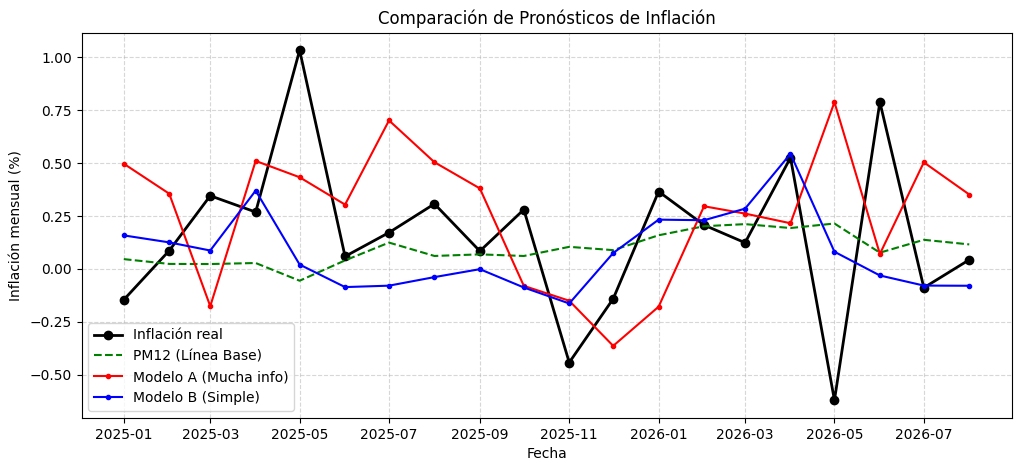

Los cinco meses con más error (promedio de los tres modelos):


,real,PM12,Modelo A,Modelo B,error PM12,error Modelo A,error Modelo B,error promedio
fecha,,,,,,,,
2026-05,-0.62,0.21,0.79,0.08,0.84,1.41,0.70,0.98
2025-05,1.03,-0.06,0.43,0.02,1.09,0.60,1.01,0.90
2026-06,0.79,0.08,0.07,-0.03,0.71,0.72,0.82,0.75
2025-01,-0.15,0.05,0.50,0.16,0.19,0.64,0.30,0.38
2025-11,-0.44,0.10,-0.15,-0.16,0.55,0.29,0.28,0.37


In [91]:
# Escribe aquí el código del paso
plt.figure(figsize=(12, 5))
plt.plot(test.index, test['inflacion'], 'ko-', label='Inflación real', linewidth=2)
plt.plot(test.index, test['pm12'], 'g--', label='PM12 (Línea Base)')
plt.plot(test.index, pron_A, 'r.-', label='Modelo A (Mucha info)')
plt.plot(test.index, pron_B, 'b.-', label='Modelo B (Simple)')
plt.title('Comparación de Pronósticos de Inflación')
plt.xlabel('Fecha')
plt.ylabel('Inflación mensual (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Los meses con más error (Corregido para usar test['inflacion'])
errores = pd.DataFrame({'real': test['inflacion'], 'PM12': test['pm12'], 'Modelo A': pron_A, 'Modelo B': pron_B})
for col in ['PM12', 'Modelo A', 'Modelo B']:
    errores[f'error {col}'] = (errores['real'] - errores[col]).abs()
errores['error promedio'] = errores[['error PM12', 'error Modelo A', 'error Modelo B']].mean(axis=1)
errores.index = errores.index.strftime('%Y-%m')
print('Los cinco meses con más error (promedio de los tres modelos):')
display(errores.sort_values('error promedio', ascending=False).head(5).round(2))

# Preguntas

Responde con tus propios resultados, en tus palabras. Escribe debajo de cada pregunta.

**Pregunta 1.** Anota el error (MAE) en Test del PM12, del Modelo A y del Modelo B. ¿Cuál ganó y por cuánto?

**Tu respuesta:**
| Modelo | MAE en Test (pp) | Frente al PM12 |
|---|---:|---|
| PM12 (línea base) | 0,286 | — |
| Modelo A (12 rezagos, desde 2006) | 0,427 | +0,141 (49 % **más** error) |
| Modelo B (PM12 + mes, desde 2015) | **0,270** | −0,016 (5,5 % **menos** error)|

**Ganó el Modelo B**, pero por muy poco: se equivoca 0,016 puntos porcentuales menos que el PM12 y le gana solo en la mitad de los meses. Frente al Modelo A la diferencia sí es grande (0,157 pp). El Modelo A pierde incluso contra el PM12, que no necesita entrenarse.



**Pregunta 2.** El Modelo B usa menos columnas y menos años que el Modelo A. ¿Por qué crees que aun así se equivoca menos (o más)?

**Tu respuesta:** El Modelo B se equivoca menos porque recibe **mejor información, no más información**.

- **El PM12 ya resume la tendencia.** En lugar de doce rezagos sueltos y ruidosos, B recibe un número que ya promedia ese ruido. La red solo tiene que aprender a **ajustar** el PM12 según el mes del año, como un factor estacional.
- **El Modelo A aprende de más.** Su error en Train (0,248) es mucho menor que en Test (0,427): aprende patrones de los meses de entrenamiento que no se repiten. Además da mucho peso a datos sueltos del pasado: en mayo de 2026 pronosticó +0,79 % porque doce meses antes (mayo de 2025) hubo un salto de +1,03 %, y la inflación real fue −0,62 %. Copió un choque que no se repitió.
- **Los años antiguos se parecen poco al presente.** A aprende desde 2006 e incluye la inflación más alta de 2008. B aprende desde 2015, con meses más parecidos a los del Test.

No es por tener menos parámetros: B tiene 121 y A 113. La diferencia está en qué columnas recibe cada red.

**Pregunta 3.** Mira el gráfico del Test. ¿En qué meses se equivocan más los modelos y por qué crees que pasa?

**Tu respuesta:** Los modelos se equivocan más en los meses con **saltos bruscos** de la inflación:

| Mes | Inflación real | Error PM12 | Error A | Error B |
|---|---:|---:|---:|---:|
| may-2026 | −0,62 % | 0,84 | 1,41 | 0,70 |
| may-2025 | +1,03 % | 1,09 | 0,60 | 1,01 |
| jun-2026 | +0,79 % | 0,71 | 0,72 | 0,82 |
| nov-2025 | −0,44 % | 0,55 | 0,29 | 0,28 |

Pasa porque esos saltos responden a **choques puntuales** (cambios de precios de bienes o servicios específicos) que no estaban en los meses anteriores. Los modelos solo ven el pasado de la propia inflación, así que no pueden anticiparlos. El PM12 y el Modelo B pronostican siempre cerca del promedio: no ven venir el choque, pero tampoco lo agrandan. El Modelo A tiene el peor error del Test (mayo de 2026) porque tomó el salto de mayo de 2025 como si fuera a repetirse.

**Pregunta 4.** ¿Qué modelo escogerías para pronosticar la inflación y por qué? Piensa en la precisión, en qué tan fácil es de explicar y en qué tan confiable es.

**Tu respuesta:** con estos resultados escogería el **PM12** como pronóstico principal y dejaría el **Modelo B** como alternativa en prueba.

- **Precisión:** B tiene el menor error (0,270 frente a 0,286), pero la ventaja es de solo 0,016 pp, medida en 20 meses, y le gana al PM12 en apenas 10 de ellos. Es prácticamente un empate. El Modelo A queda descartado: 49 % más error.
- **Facilidad para explicarlo:** el PM12 se explica en una frase y cualquiera lo puede recalcular. B se puede contar como "el PM12 ajustado por el mes del año", pero sus 121 pesos no se pueden leer uno por uno.
- **Confianza:** el PM12 no depende de semillas, tasas de aprendizaje ni parada temprana. El resultado de una red sí cambia con esas decisiones: con un empate tan estrecho, no hay evidencia suficiente para reemplazar la línea base.

Antes de adoptar el Modelo B lo validaría con un origen móvil en varios años y promediando varias semillas. Si mantiene la ventaja, lo usaría combinado con el PM12.

## Conclusión

En 4 a 6 líneas: ¿qué aprendiste en este laboratorio sobre las redes neuronales? ¿Cuándo vale la pena usar una y cuándo basta con algo simple como el PM12?

**Tu conclusión:** una red neuronal no mejora por ser más compleja ni por recibir más datos: el Modelo A, con 12 rezagos y casi 20 años, aprendió patrones que no se repiten y perdió contra el PM12 por un 49 %. Lo que más ayudó fue darle a la red **variables bien pensadas**: el Modelo B, que parte del PM12 y solo aprende el efecto del mes, fue el único que lo mejoró, aunque por muy poco. Con series mensuales cortas, una red vale la pena solo si complementa a un buen punto de partida y se valida con cuidado; en otro caso basta el PM12, que es simple, transparente y difícil de superar. Las redes rinden más con muchos datos (miles de clientes, imágenes o texto) que con una sola serie de 20 años.

## Calificación (sobre 100)

| Qué se califica | Puntos |
|---|---:|
| Notebook completo y ejecutado (partes 1 y 2), con nombre y en el mismo orden | 20 |
| Modelo A construido, entrenado y con su error | 15 |
| Modelo B construido, entrenado y con su error | 15 |
| Tabla y gráfico de comparación (Paso 2.8) | 10 |
| Preguntas 1 a 4 (8 puntos cada una) | 32 |
| Conclusión | 8 |
| **Total** | **100** |